<a href="https://colab.research.google.com/github/amulyasundaresan/Midterm-1/blob/main/Notebooks/2026_10_30_%E2%80%94_Midterm_Progress_%E2%80%94_Lab_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DS2002 · Midterm Progress

**Lab — 2026-10-30 · Fall 2026**  

---

## Lab 10 — Midterm progress, week 2 of 3

One submission per team. Questions 1 through 3 should be substantially answered by now — not polished, but answered, with a number and a chart each.

Presentations are Monday. If a question is not working, this is the last checkpoint where there is time to do something about it, so report the actual state rather than the intended one.

## Previous Work

Lab deliverables are in next section

In [ ]:
import os, re, time, glob, sqlite3, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 40)
print('pandas', pd.__version__)

pandas 2.2.3


In [ ]:
# ---- Decision log: every cleaning decision goes through log() -------------------------------
DECISIONS = []

def log(file_name, step, decision, rows_affected):
    DECISIONS.append({'file': file_name, 'step': step, 'decision': decision,
                      'rows_affected': int(rows_affected)})
    print(f"[{file_name}] {step}: {decision} ({int(rows_affected):,} row(s))")

def show_log():
    return pd.DataFrame(DECISIONS)

In [ ]:
GITHUB_RAW = 'https://raw.githubusercontent.com/amulyasundaresan/Midterm-1/refs/heads/main/Data'

def get_data(filename):
    for folder in ['data', '../data', '/content', '.'] + glob.glob('/kaggle/input/*'):
        path = os.path.join(folder, filename)
        if os.path.exists(path):
            return path
    os.makedirs('data', exist_ok=True)
    dest = os.path.join('data', filename)
    print(f'{filename} not found locally, downloading from GitHub...')
    urllib.request.urlretrieve(f'{GITHUB_RAW}/{filename}', dest)
    return dest

RAW = {
    'transactions': pd.read_csv(get_data('walmart_transactions.csv')),
    'stores':       pd.read_csv(get_data('store_locations.csv')),
    'products':     pd.read_csv(get_data('product_catalog.csv')),
    'dcs':          pd.read_csv(get_data('distribution_centers.csv')),
}

# The SQLite database (used mostly for Q5). Keep the connection open for your SQL queries.
conn = sqlite3.connect(get_data('inventory_and_sales.db'))
print('tables in the database:', pd.read_sql("SELECT name FROM sqlite_master WHERE type='table'", conn)['name'].tolist())
RAW['inventory'] = pd.read_sql('SELECT * FROM inventory_levels', conn)
RAW['daily_sales'] = pd.read_sql('SELECT * FROM daily_sales_summary', conn)

for name, df in RAW.items():
    print(f'{name:13s} {df.shape[0]:>7,} rows x {df.shape[1]} cols')

tables in the database: ['daily_sales_summary', 'inventory_levels']
transactions   25,562 rows x 8 cols
stores             14 rows x 8 cols
products           45 rows x 7 cols
dcs                 5 rows x 8 cols
inventory       4,320 rows x 6 cols
daily_sales     3,600 rows x 5 cols


In [ ]:
CATEGORY_MAP = {
    'breakfast': 'Breakfast', 'breakfast foods': 'Breakfast',
    'emergency': 'Emergency Supplies', 'emergency supplies': 'Emergency Supplies',
    'grocery': 'Grocery', 'groceries': 'Grocery',
    'baby': 'Baby Products', 'baby products': 'Baby Products',
    'alcohol': 'Alcohol', 'alcohol drinks': 'Alcohol', 'alcoholic beverages': 'Alcohol',
    'game & entertainment': 'Game & Entertainment', 'games & entertainment': 'Game & Entertainment',
    'game': 'Game & Entertainment', 'entertainment': 'Game & Entertainment',
    'health': 'Health', 'health & wellness': 'Health',
    'household': 'Household', 'household essentials': 'Household',
    'electronics': 'Electronics',
    'snacks': 'Snacks',
}
CANONICAL_CATEGORIES = set(CATEGORY_MAP.values())

def clean_category(s):
    key = s.astype('string').str.strip().str.lower()
    return key.map(CATEGORY_MAP).fillna(key.str.title())

In [ ]:
# canonical_sku -> (display name, [every SKU variant seen in the catalog / transactions / database])
SKU_FAMILIES = {
    'POPTART-STRAW': ('Pop-Tarts Strawberry',    ['PT-12', 'SKU#459812', 'POPTART-STRAW', 'PT_STRAWBERRY']),
    'WTR_24PK':      ('Bottled Water 24-Pack',   ['WTR-24', 'WATER24PK', 'WTR_24PK']),
    'BATT_AA_4PK':   ('AA Batteries 4-Pack',     ['BATT-100', 'BAT-AA4', 'BATT_AA_4PK']),
    'FLASH-01':      ('LED Flashlight',          ['FLASH-01', 'LED-FLASH']),
    'BEER-24':       ('Light Beer 24-Pack',      ['BEER-24', 'LTBEER24']),
    'MONOPOLY-01':   ('Monopoly Board Game',     ['BG-MONO', 'MONOPOLY-01', 'GAME-MONO']),
    'CARDS-01':      ('Playing Cards',           ['CARDS-01', 'PLAYCARD-STD']),
    'STREAM-01':     ('Roku Streaming Stick',    ['STREAM-01', 'ROKU-STD']),
    'CNSOUP-01':     ('Canned Soup',             ['SOUP-CAN', 'CNSOUP-01']),
    'BREAD-WH':      ('White Bread',             ['BREAD-WH', 'WHITEBREAD']),
    'PB-16':         ('Peanut Butter 16oz',      ['PB-16', 'PNUTBTR-16']),
    'CNDL-EM':       ('Emergency Candles',       ['CNDL-EM', 'CANDLE-EMRG']),
    'FAID-01':       ('First-Aid Kit',           ['FAID-01', 'FIRSTAID-KIT']),
    'CHRG-PORT':     ('Portable Charger',        ['CHRG-PORT', 'PORTCHARGER']),
    'CHIPS-VP':      ('Chips Variety Pack',      ['CHIPS-VP', 'CHIPVARIETY']),
    'PAPERTOWEL6':   ('Paper Towels 6-Pack',     ['PTOWEL-6', 'PAPERTOWEL6']),
    'TOILETPAPER12': ('Toilet Paper 12-Roll',    ['TP-12', 'TOILETPAPER12']),
    'DIAPERS-3':     ('Baby Diapers Size 3',     ['DIAP-S3', 'DIAPERS-3']),
    'BABYFORMULA':   ('Infant Formula',          ['BFORM-01', 'BABYFORMULA']),
    'TARP-HD':       ('Heavy Duty Tarp',         ['TARP-HD', 'HDTARP-01']),
}
SKU_TO_CANON = {v: canon for canon, (_, variants) in SKU_FAMILIES.items() for v in variants}
CANON_NAME   = {canon: name for canon, (name, _) in SKU_FAMILIES.items()}

# SKUs that appear ONLY in the inventory database and in no catalog. We do not guess what they are.
ORPHAN_SKUS = {'UNKNOWN-99', 'LEGACY-PT', 'OLD-BATT-50', 'MISC-001'}

# Safety net: every SKU in every file must be either mapped or a known orphan.
all_skus = (set(RAW['transactions']['sku'].str.strip()) | set(RAW['products']['sku'].str.strip())
            | set(RAW['inventory']['sku'].str.strip().str.upper()))
unmapped = all_skus - set(SKU_TO_CANON) - ORPHAN_SKUS
assert not unmapped, f'SKUs with no mapping, add them to SKU_FAMILIES: {unmapped}'
print(f'{len(SKU_TO_CANON)} SKU variants map to {len(SKU_FAMILIES)} canonical products; {len(ORPHAN_SKUS)} orphan SKUs flagged')

45 SKU variants map to 20 canonical products; 4 orphan SKUs flagged


In [ ]:
# Small cleaning helpers shared by every file
def strip_text(df):
    # Strip leading/trailing spaces in every text column. Works on pandas 2 (object) and pandas 3 (str).
    # Returns the cleaned frame and how many rows had at least one value changed.
    df = df.copy()
    changed = pd.Series(False, index=df.index)
    for c in df.columns:
        if df[c].dtype == object or pd.api.types.is_string_dtype(df[c]):
            old = df[c].astype('string')
            new = old.str.strip()
            changed |= (old != new).fillna(False)
            df[c] = new
    return df, int(changed.sum())

def clean_store_id(s):
    # FL710, fl_710, ' FL-710', 'FL 710' -> 'FL-710'
    s = s.astype('string').str.strip().str.upper().str.replace(r'[^A-Z0-9]', '', regex=True)
    return s.str.replace(r'^FL(\d+)$', r'FL-\1', regex=True)

def to_money(s):
    # '$9.64', ' 19.32 ', '3.15' -> float
    return pd.to_numeric(s.astype('string').str.replace(r'[$,\s]', '', regex=True), errors='coerce')

# Timestamps arrive in 5 different layouts. Explicit formats, tried in order, so nothing is guessed.
# (For the slash and dash layouts the first number is always 09 and the second runs 1-30, so they are month-first.)
TS_FORMATS = [
    ('%Y-%m-%d %H:%M:%S', '2024-09-02 20:30:20'),
    ('%Y-%m-%dT%H:%M:%S', '2024-09-13T09:48:13'),
    ('%m/%d/%Y %H:%M',    '09/15/2024 09:26'),
    ('%d-%b-%Y %H:%M',    '15-Sep-2024 09:26'),
    ('%m-%d-%Y %H:%M:%S', '09-12-2024 18:24:47'),
]
MISSING_TOKENS = ['NULL', 'N/A', 'NA', 'nan', 'NaN', 'None', '']

def parse_timestamps(s, file_name='walmart'):
    s = s.astype('string').str.strip()
    s = s.mask(s.isin(MISSING_TOKENS))
    out = pd.Series(pd.NaT, index=s.index, dtype='datetime64[ns]')
    for fmt, example in TS_FORMATS:
        todo = out.isna() & s.notna()
        parsed = pd.to_datetime(s[todo], format=fmt, errors='coerce')
        out.loc[todo] = parsed
        log(file_name, 'Timestamp', f'parsed layout {fmt}  e.g. {example}', parsed.notna().sum())
    return out

In [ ]:
NEG_QTY_POLICY = 'abs'      # 'abs' | 'drop' | 'keep'   <- TEAM DECISION, justify it in the log

def add_best_date(df):
    # Missing timestamps: transaction ids are nearly time-ordered (rank correlation ~0.995). If the nearest known
    # transaction before AND after both fall on the same day, the missing one is on that day too.
    # We only recover the DATE, never the hour. Rows where the neighbours disagree stay NaT.
    tmp = df.sort_values('txn_num')
    known = tmp['timestamp'].dt.normalize()
    prev, nxt = known.ffill(), known.bfill()
    recoverable = known.isna() & (prev == nxt)
    best = known.copy()
    best[recoverable] = prev[recoverable]
    df['date_best'] = best                       # aligned back on the index
    df['date_imputed'] = recoverable.astype(int)
    return df

def clean_walmart_transactions(df_raw, neg_policy=None):
    neg_policy = neg_policy or NEG_QTY_POLICY
    df = df_raw.copy()
    df.columns = df.columns.str.strip().str.lower()
    df, n_ws = strip_text(df)
    log('walmart', 'Whitespace', 'stripped leading/trailing spaces in text columns', n_ws)

    n = len(df)
    df = df.drop_duplicates().copy()
    log('walmart', 'Duplicates', 'dropped exact duplicate rows', n - len(df))
    assert df['transaction_id'].is_unique, 'transaction_id should be unique after de-duplication'

    before = df['store_id'].copy()
    df['store_id'] = clean_store_id(df['store_id'])
    log('walmart', 'Store ID', "standardized to 'FL-###'", (before != df['store_id']).sum())

    has_dollar = df['unit_price'].astype('string').str.contains(r'\$', na=False).sum()
    df['unit_price'] = to_money(df['unit_price'])
    log('walmart', 'Price', "removed '$' and spaces, converted unit_price to float", has_dollar)
    log('walmart', 'Price', 'unit_price values that could not be parsed (left NaN)', df['unit_price'].isna().sum())

    df['quantity'] = pd.to_numeric(df['quantity'], errors='coerce')
    df['is_neg_qty'] = (df['quantity'] < 0).astype(int)
    n_neg = int(df['is_neg_qty'].sum())
    if neg_policy == 'abs':
        df['quantity_clean'] = df['quantity'].abs()
        log('walmart', 'Negative qty', "policy 'abs': sign flipped, rows kept (assumed sign typo)", n_neg)
    elif neg_policy == 'drop':
        df = df[df['quantity'] >= 0].copy()
        df['quantity_clean'] = df['quantity']
        log('walmart', 'Negative qty', "policy 'drop': rows removed", n_neg)
    else:
        df['quantity_clean'] = df['quantity']
        log('walmart', 'Negative qty', "policy 'keep': left negative, flagged in is_neg_qty", n_neg)

    before = df['category'].copy()
    df['category'] = clean_category(df['category'])
    log('walmart', 'Category', 'mapped spelling variants to 10 canonical categories', (before != df['category']).sum())
    assert set(df['category'].dropna()) <= CANONICAL_CATEGORIES, 'unknown category slipped through'

    # SKU: keep the raw sku, add canonical columns
    df['canonical_sku'] = df['sku'].map(SKU_TO_CANON)
    df['canonical_product'] = df['canonical_sku'].map(CANON_NAME)
    changed = (df['sku'] != df['canonical_sku']).sum()
    log('walmart', 'SKU', 'added canonical_sku / canonical_product (raw sku kept)', changed)
    assert df['canonical_sku'].notna().all(), 'a transaction SKU has no mapping'

    # Timestamps
    df['txn_num'] = df['transaction_id'].str.extract(r'(\d+)')[0].astype(int)
    df['timestamp'] = parse_timestamps(df['timestamp'])
    df['timestamp_missing'] = df['timestamp'].isna().astype(int)
    log('walmart', 'Timestamp', 'no timestamp at all (kept as NaT, flagged timestamp_missing)', df['timestamp_missing'].sum())
    df['date'] = df['timestamp'].dt.normalize()        # strict: only from a real timestamp
    df['hour'] = df['timestamp'].dt.hour
    df = add_best_date(df)
    log('walmart', 'Timestamp', 'recovered the DATE from neighbouring transaction ids (date_best, flagged date_imputed)', df['date_imputed'].sum())
    log('walmart', 'Timestamp', 'still no date after recovery (excluded from daily charts)', df['date_best'].isna().sum())

    df['revenue'] = df['quantity_clean'] * df['unit_price']
    return df.sort_values('txn_num').reset_index(drop=True)

In [ ]:
def clean_product_catalog(df_raw):
    df = df_raw.copy()
    df.columns = df.columns.str.strip().str.lower()
    df, n_ws = strip_text(df)
    log('products', 'Whitespace', 'stripped leading/trailing spaces in text columns', n_ws)

    n = len(df); df = df.drop_duplicates().copy()
    log('products', 'Duplicates', 'dropped exact duplicate rows', n - len(df))

    before = df['category'].copy()
    df['category'] = clean_category(df['category'])
    log('products', 'Category', 'mapped to canonical categories', (before != df['category']).sum())

    df['canonical_sku'] = df['sku'].map(SKU_TO_CANON)
    df['canonical_product'] = df['canonical_sku'].map(CANON_NAME)
    log('products', 'SKU', 'added canonical_sku / canonical_product', df['canonical_sku'].notna().sum())

    df['unit_cost'] = pd.to_numeric(df['unit_cost'], errors='coerce')
    df['unit_cost_imputed'] = df['unit_cost'].isna().astype(int)
    # a missing cost is best estimated from the SAME product under another SKU; fall back to category median
    fam_med = df.groupby('canonical_sku')['unit_cost'].transform('median')
    cat_med = df.groupby('category')['unit_cost'].transform('median')
    df['unit_cost'] = df['unit_cost'].fillna(fam_med).fillna(cat_med)
    log('products', 'Missing', 'unit_cost filled with the median of the same canonical product (else category)', df['unit_cost_imputed'].sum())

    n_sub = df['subcategory'].isna().sum()
    df['subcategory'] = df['subcategory'].fillna('Unknown')
    log('products', 'Missing', "subcategory filled with 'Unknown'", n_sub)

    old_ps = df['package_size'].astype('string')
    df['package_size'] = old_ps.str.lower().str.replace('-', ' ', regex=False)
    log('products', 'Format', 'package_size lower-cased, hyphens removed (this column is noisy: do not use it to match products)', (old_ps != df['package_size']).sum())
    return df

def clean_store_locations(df_raw):
    df = df_raw.copy()
    df.columns = df.columns.str.strip().str.lower()
    df, n_ws = strip_text(df)
    log('stores', 'Whitespace', 'stripped leading/trailing spaces (e.g. region " Panhandle")', n_ws)

    before = df['store_id'].copy()
    df['store_id'] = clean_store_id(df['store_id'])
    log('stores', 'Store ID', "standardized to 'FL-###'", (before != df['store_id']).sum())

    n = len(df); df = df.drop_duplicates(subset=['store_id'], keep='first').copy()
    log('stores', 'Duplicates', 'dropped repeat store rows (FL239 = FL-239, FL_287 = FL-287)', n - len(df))

    st = df['state'].astype('string').str.upper().str.replace('.', '', regex=False)
    new_state = st.replace({'FLORIDA': 'FL', 'FLA': 'FL'})
    log('stores', 'State', "FL / Florida / Fla. -> 'FL'", (df['state'] != new_state).sum())
    df['state'] = new_state

    df['latitude'] = pd.to_numeric(df['latitude'], errors='coerce')
    df['longitude'] = pd.to_numeric(df['longitude'], errors='coerce')
    n_missing = (df['latitude'].isna() | df['longitude'].isna()).sum()
    # EXTERNAL FACT, not derived from the data: Tallahassee city-centre coordinates
    CITY_COORDS = {'Tallahassee': (30.4383, -84.2807)}
    for city, (lat, lon) in CITY_COORDS.items():
        m = df['city'] == city
        df.loc[m & df['latitude'].isna(), 'latitude'] = lat
        df.loc[m & df['longitude'].isna(), 'longitude'] = lon
    log('stores', 'Missing', 'filled missing lat/lon from known Tallahassee city-centre coordinates (external reference)', n_missing)
    assert df[['latitude', 'longitude']].notna().all().all(), 'a store still has no coordinates'
    return df.reset_index(drop=True)

def clean_distribution_center(df_raw):
    df = df_raw.copy()
    df.columns = df.columns.str.strip().str.lower()
    df, n_ws = strip_text(df)
    log('dcs', 'Whitespace', 'stripped leading/trailing spaces in text columns', n_ws)
    n = len(df); df = df.drop_duplicates().copy()
    log('dcs', 'Duplicates', 'dropped exact duplicate rows', n - len(df))

    tilde = df['surge_capacity'].astype('string').str.contains('~', na=False).sum()
    df['surge_capacity'] = df['surge_capacity'].astype('string').str.replace('~', '', regex=False)
    log('dcs', 'Format', "removed '~' from surge_capacity (it was an estimate)", tilde)

    for c in ['avg_daily_shipments', 'surge_capacity', 'distance_to_orlando_mi', 'cost_per_shipment']:
        df[c] = pd.to_numeric(df[c], errors='coerce')
    log('dcs', 'Numeric', 'converted numeric columns', len(df))

    df['cost_imputed'] = df['cost_per_shipment'].isna().astype(int)
    median_cost = df['cost_per_shipment'].median()
    if pd.notna(median_cost):
        df['cost_per_shipment'] = (
            df['cost_per_shipment'].fillna(median_cost)
    )
    log('dcs', 'Missing', 'cost_per_shipment filled with median (flagged cost_imputed; 5 rows only, treat with caution)', df['cost_imputed'].sum())
    return df

In [ ]:
def clean_inventory(df_raw):
    df = df_raw.copy()
    df.columns = df.columns.str.strip().str.lower()
    df, n_ws = strip_text(df)
    log('inventory', 'Whitespace', 'stripped leading/trailing spaces in text columns', n_ws)
    n = len(df); df = df.drop_duplicates().copy()
    log('inventory', 'Duplicates', 'dropped exact duplicate rows', n - len(df))

    before = df['store_id'].copy()
    df['store_id'] = clean_store_id(df['store_id'])
    log('inventory', 'Store ID', "standardized to 'FL-###'", (before != df['store_id']).sum())

    df['date'] = pd.to_datetime(df['date'], format='%Y-%m-%d', errors='coerce')
    log('inventory', 'Date', 'parsed (unparseable would be NaT)', df['date'].isna().sum())

    for c in ['units_on_hand', 'units_on_order', 'reorder_point']:
        df[c] = pd.to_numeric(df[c], errors='coerce')

    df['sku'] = df['sku'].str.upper()
    df['canonical_sku'] = df['sku'].map(SKU_TO_CANON)
    df['is_orphan_sku'] = df['sku'].isin(ORPHAN_SKUS).astype(int)
    df.loc[df['is_orphan_sku'] == 1, 'canonical_sku'] = 'UNRESOLVED'
    df['canonical_product'] = df['canonical_sku'].map(CANON_NAME).fillna('UNRESOLVED')
    log('inventory', 'SKU', 'added canonical_sku (raw kept)', df['canonical_sku'].ne(df['sku']).sum())
    log('inventory', 'SKU', 'orphan SKUs (UNKNOWN-99, LEGACY-PT, OLD-BATT-50, MISC-001) flagged, NOT merged: not in any catalog', df['is_orphan_sku'].sum())
    assert df['canonical_sku'].notna().all()

    df['on_order_missing'] = df['units_on_order'].isna().astype(int)
    df['units_on_order'] = df['units_on_order'].fillna(0)
    log('inventory', 'Missing', 'units_on_order NaN -> 0 (ASSUMPTION: nothing on order; flagged on_order_missing)', df['on_order_missing'].sum())
    return df

def clean_daily_sales(df_raw):
    df = df_raw.copy()
    df.columns = df.columns.str.strip().str.lower()
    df, n_ws = strip_text(df)
    log('daily_sales', 'Whitespace', 'stripped leading/trailing spaces in text columns', n_ws)
    n = len(df); df = df.drop_duplicates().copy()
    log('daily_sales', 'Duplicates', 'dropped exact duplicate rows', n - len(df))

    before = df['store_id'].copy()
    df['store_id'] = clean_store_id(df['store_id'])
    log('daily_sales', 'Store ID', "standardized to 'FL-###'", (before != df['store_id']).sum())

    # two date layouts live in this table: 2024-09-01 and 20240901
    s = df['date'].astype('string')
    d_iso = pd.to_datetime(s, format='%Y-%m-%d', errors='coerce')
    d_compact = pd.to_datetime(s, format='%Y%m%d', errors='coerce')
    df['date'] = d_iso.fillna(d_compact)
    log('daily_sales', 'Date', 'parsed YYYY-MM-DD and compact YYYYMMDD layouts', d_compact.notna().sum())
    log('daily_sales', 'Date', 'dates that could not be parsed', df['date'].isna().sum())

    before = df['category'].copy()
    df['category'] = clean_category(df['category'])
    log('daily_sales', 'Category', 'mapped to canonical categories', (before != df['category']).sum())

    df['total_units'] = pd.to_numeric(df['total_units'], errors='coerce')
    df['total_revenue'] = pd.to_numeric(df['total_revenue'], errors='coerce')
    frac = (df['total_units'] % 1 != 0).sum()
    df['units_fractional'] = (df['total_units'] % 1 != 0).astype(int)
    log('daily_sales', 'Check', 'total_units has non-whole values like 71.5 (units cannot be fractional): flagged, NOT changed. Look into this for Q5', frac)
    return df

In [ ]:
DECISIONS.clear()          # so re-running this cell never double-logs

transactions = clean_walmart_transactions(RAW['transactions'])
products     = clean_product_catalog(RAW['products'])
stores       = clean_store_locations(RAW['stores'])
dcs          = clean_distribution_center(RAW['dcs'])
inventory    = clean_inventory(RAW['inventory'])
daily_sales  = clean_daily_sales(RAW['daily_sales'])

[walmart] Whitespace: stripped leading/trailing spaces in text columns (2,331 row(s))
[walmart] Duplicates: dropped exact duplicate rows (30 row(s))
[walmart] Store ID: standardized to 'FL-###' (3,607 row(s))
[walmart] Price: removed '$' and spaces, converted unit_price to float (3,026 row(s))
[walmart] Price: unit_price values that could not be parsed (left NaN) (0 row(s))
[walmart] Negative qty: policy 'abs': sign flipped, rows kept (assumed sign typo) (130 row(s))
[walmart] Category: mapped spelling variants to 10 canonical categories (19,358 row(s))
[walmart] SKU: added canonical_sku / canonical_product (raw sku kept) (13,988 row(s))
[walmart] Timestamp: parsed layout %Y-%m-%d %H:%M:%S  e.g. 2024-09-02 20:30:20 (12,169 row(s))
[walmart] Timestamp: parsed layout %Y-%m-%dT%H:%M:%S  e.g. 2024-09-13T09:48:13 (2,504 row(s))
[walmart] Timestamp: parsed layout %m/%d/%Y %H:%M  e.g. 09/15/2024 09:26 (5,027 row(s))
[walmart] Timestamp: parsed layout %d-%b-%Y %H:%M  e.g. 15-Sep-2024 09:26 (2,

In [ ]:
# Rows before and after, one line per file (the checkpoint asks for this)
CLEAN = {'transactions': transactions, 'stores': stores, 'products': products,
         'dcs': dcs, 'inventory': inventory, 'daily_sales': daily_sales}
rows = pd.DataFrame({'raw_rows': {k: len(RAW[k]) for k in CLEAN},
                     'clean_rows': {k: len(v) for k, v in CLEAN.items()}})
rows['rows_removed'] = rows['raw_rows'] - rows['clean_rows']
rows

,raw_rows,clean_rows,rows_removed
transactions,25562,25532,30
stores,14,12,2
products,45,45,0
dcs,5,5,0
inventory,4320,4320,0
daily_sales,3600,3600,0


In [ ]:
sku_map_table = (products[['sku', 'canonical_sku', 'canonical_product', 'category']]
                 .sort_values(['canonical_product', 'sku']).reset_index(drop=True))
group_sizes = sku_map_table.groupby('canonical_product')['sku'].nunique().sort_values(ascending=False)

print(f"distinct SKUs in the raw transactions : {RAW['transactions']['sku'].nunique()}")
print(f"canonical products after consolidation : {transactions['canonical_sku'].nunique()}")
print(f"largest consolidated group             : {group_sizes.index[0]} ({group_sizes.iloc[0]} SKUs)")
print('groups with 3+ SKUs                    :', group_sizes[group_sizes >= 3].to_dict())
print()
print('Pop-Tarts mapping:')
sku_map_table[sku_map_table['canonical_product'] == 'Pop-Tarts Strawberry']

distinct SKUs in the raw transactions : 45
canonical products after consolidation : 20
largest consolidated group             : Pop-Tarts Strawberry (4 SKUs)
groups with 3+ SKUs                    : {'Pop-Tarts Strawberry': 4, 'AA Batteries 4-Pack': 3, 'Monopoly Board Game': 3, 'Bottled Water 24-Pack': 3}

Pop-Tarts mapping:


,sku,canonical_sku,canonical_product,category
33,POPTART-STRAW,POPTART-STRAW,Pop-Tarts Strawberry,Breakfast
34,PT-12,POPTART-STRAW,Pop-Tarts Strawberry,Breakfast
35,PT_STRAWBERRY,POPTART-STRAW,Pop-Tarts Strawberry,Breakfast
36,SKU#459812,POPTART-STRAW,Pop-Tarts Strawberry,Breakfast


In [ ]:
# Fragmented vs consolidated, for Pop-Tarts, in units sold over the whole month
pt = transactions[transactions['canonical_sku'] == 'POPTART-STRAW']
fragmented = pt.groupby('sku')['quantity_clean'].sum().sort_values(ascending=False)
print('Fragmented view (one number per SKU):')
print(fragmented.to_string())
print(f"\nConsolidated view: {int(fragmented.sum()):,} units, across {fragmented.size} SKUs")
print(f"Largest single SKU alone shows only {fragmented.iloc[0] / fragmented.sum():.0%} of true Pop-Tarts volume")

Fragmented view (one number per SKU):
sku
PT-12            1385
POPTART-STRAW    1306
PT_STRAWBERRY    1270
SKU#459812       1257

Consolidated view: 5,218 units, across 4 SKUs
Largest single SKU alone shows only 27% of true Pop-Tarts volume


In [ ]:
BASE = 'https://archive-api.open-meteo.com/v1/archive'
RETRY_STATUSES = {429, 500, 502, 503, 504}

def _get_json(url, params, tries=3):
    for attempt in range(1, tries + 1):
        try:
            r = requests.get(url, params=params, timeout=15)
        except (requests.Timeout, requests.ConnectionError):
            if attempt == tries:
                raise
            time.sleep(2 ** attempt)
            continue
        if r.status_code in RETRY_STATUSES:
            if attempt == tries:
                r.raise_for_status()
            time.sleep(2 ** attempt)
            continue
        r.raise_for_status()                 # any other bad status fails loudly
        return r.json()

def fetch_weather(start, end, lat=28.5383, lon=-81.3792, tries=3):
    # Daily weather for one point. Defaults to the Orlando store (FL-239).
    params = {'latitude': lat, 'longitude': lon, 'start_date': start, 'end_date': end,
              'daily': 'precipitation_sum,windspeed_10m_max', 'timezone': 'America/New_York'}
    frame = pd.DataFrame(_get_json(BASE, params, tries)['daily']).rename(columns={'time': 'date'})
    frame['date'] = pd.to_datetime(frame['date'])
    frame['source'] = 'open-meteo'
    return frame

# Saved copy of the same Open-Meteo data (Orlando, Sept 1-30 2024) from the lab, for when the API is down
FALLBACK = pd.DataFrame({
    'date': pd.date_range('2024-09-01', periods=30),
    'precipitation_sum': [3.0, 12.4, 24.9, 22.1, 23.1, 9.3, 6.8, 94.7, 28.0, 14.4,
                          12.0, 0.7, 0.6, 21.1, 1.2, 7.9, 2.3, 13.3, 1.4, 0.7,
                          0.4, 2.2, 1.3, 0.3, 6.4, 15.2, 2.5, 18.0, 4.6, 3.3],
    'windspeed_10m_max': [18.8, 13.5, 22.8, 15.5, 15.2, 9.0, 14.2, 12.6, 11.5, 14.3,
                          15.8, 12.1, 10.4, 17.4, 9.0, 13.3, 12.4, 9.3, 12.9, 15.3,
                          19.9, 17.9, 16.6, 17.7, 27.2, 48.8, 45.1, 19.8, 11.7, 8.6],
    'source': 'fallback sample',
})

def clean_weather(df_raw):
    df = df_raw.copy()
    df.columns = df.columns.str.strip().str.lower()
    n = len(df); df = df.drop_duplicates(subset=['date']).copy()
    log('weather', 'Duplicates', 'dropped repeated dates', n - len(df))
    df['date'] = pd.to_datetime(df['date'], errors='coerce')
    for c in [c for c in df.columns if c not in ('date', 'source')]:
        df[c] = pd.to_numeric(df[c], errors='coerce')
    missing = int(df.drop(columns=['date', 'source']).isna().any(axis=1).sum())
    log('weather', 'Missing', 'rows with a missing weather value, LEFT as NaN (0 wind would be a false claim)', missing)
    return df.sort_values('date').reset_index(drop=True)

In [ ]:
try:
    weather_raw = fetch_weather('2024-09-01', '2024-09-30')
    print('Live API call succeeded.')
except requests.RequestException as err:
    print('!' * 70)
    print('API CALL FAILED:', err)
    print('Using the saved fallback sample. Fix this before you submit.')
    print('!' * 70)
    weather_raw = FALLBACK.copy()

weather = clean_weather(weather_raw)
print('source:', weather['source'].iloc[0], '| rows:', len(weather))

if weather['source'].iloc[0] == 'open-meteo':
    d_rain = (weather['precipitation_sum'] - FALLBACK['precipitation_sum']).abs().max()
    d_wind = (weather['windspeed_10m_max'] - FALLBACK['windspeed_10m_max']).abs().max()
    print(f'largest difference from the saved copy: rain {d_rain:.2f} mm, wind {d_wind:.2f} km/h '
          '(if these are not ~0, find out why: units, grid cell, or a data revision)')
weather.head()

Live API call succeeded.
[weather] Duplicates: dropped repeated dates (0 row(s))
[weather] Missing: rows with a missing weather value, LEFT as NaN (0 wind would be a false claim) (0 row(s))
source: open-meteo | rows: 30
largest difference from the saved copy: rain 35.90 mm, wind 6.00 km/h (if these are not ~0, find out why: units, grid cell, or a data revision)


,date,precipitation_sum,windspeed_10m_max,source
0,2024-09-01,6.4,18.7,open-meteo
1,2024-09-02,22.0,12.7,open-meteo
2,2024-09-03,32.7,20.6,open-meteo
3,2024-09-04,21.2,12.6,open-meteo
4,2024-09-05,20.8,15.2,open-meteo


In [ ]:
def fetch_weather_hourly(lat, lon, start, end, tries=3):
    params = {'latitude': lat, 'longitude': lon, 'start_date': start, 'end_date': end,
              'hourly': 'precipitation,wind_speed_10m,pressure_msl', 'timezone': 'UTC'}
    h = pd.DataFrame(_get_json(BASE, params, tries)['hourly']).rename(columns={'time': 'time_utc'})
    h['time_utc'] = pd.to_datetime(h['time_utc']).dt.tz_localize('UTC')
    h['time_et'] = h['time_utc'].dt.tz_convert('America/New_York')       # <- the timezone alignment step
    h['date'] = h['time_et'].dt.tz_localize(None).dt.normalize()         # local calendar day, to join to sales
    h['source'] = 'open-meteo hourly'
    return h

weather_hourly = None
try:
    parts = []
    for _, s in stores.iterrows():
        # pad the UTC request by a day on each side: UTC midnight on Sept 1 is 8 pm on Aug 31 in Florida
        h = fetch_weather_hourly(s['latitude'], s['longitude'], '2024-08-31', '2024-10-01')
        h['store_id'] = s['store_id']
        parts.append(h)
        time.sleep(0.3)                                                   # be polite to a free API
    weather_hourly = pd.concat(parts, ignore_index=True)
    weather_hourly = weather_hourly[weather_hourly['date'].between('2024-09-01', '2024-09-30')].reset_index(drop=True)  # keep local Sept days only
    print(f'hourly weather: {len(weather_hourly):,} rows for {weather_hourly["store_id"].nunique()} stores')
    display(weather_hourly.head(3))
except requests.RequestException as err:
    print('Hourly weather not available right now:', err)

hourly weather: 8,640 rows for 12 stores


,time_utc,precipitation,wind_speed_10m,pressure_msl,time_et,date,source,store_id
0,2024-09-01 04:00:00+00:00,0.0,7.9,1015.2,2024-09-01 00:00:00-04:00,2024-09-01,open-meteo hourly,FL-239
1,2024-09-01 05:00:00+00:00,0.0,5.5,1015.0,2024-09-01 01:00:00-04:00,2024-09-01,open-meteo hourly,FL-239
2,2024-09-01 06:00:00+00:00,0.0,5.8,1014.5,2024-09-01 02:00:00-04:00,2024-09-01,open-meteo hourly,FL-239


In [ ]:
def checked_merge(left, right, on, name):
    n = len(left)
    out = left.merge(right, on=on, how='left', validate='many_to_one', indicator=True)
    assert len(out) == n, f'{name}: row count changed {n} -> {len(out)}'
    no_match = int((out['_merge'] != 'both').sum())
    print(f'{name}: {n:,} rows in, {len(out):,} out, {no_match} rows found no weather')
    return out.drop(columns='_merge')

weather_daily = weather[['date', 'precipitation_sum', 'windspeed_10m_max', 'source']]

# (a) the database's daily summary (by store x category x day) + weather
sales_weather = checked_merge(daily_sales, weather_daily, on='date', name='daily_sales + weather')

# (b) transactions rolled up to one row per day + weather
daily_orders = (transactions.dropna(subset=['date_best'])
                .groupby('date_best')
                .agg(orders=('transaction_id', 'count'), units=('quantity_clean', 'sum'))
                .reset_index().rename(columns={'date_best': 'date'}))
orders_weather = checked_merge(daily_orders, weather_daily, on='date', name='daily orders + weather')
orders_weather.head()

daily_sales + weather: 3,600 rows in, 3,600 out, 0 rows found no weather
daily orders + weather: 30 rows in, 30 out, 0 rows found no weather


,date,orders,units,precipitation_sum,windspeed_10m_max,source
0,2024-09-01,597,1149,6.4,18.7,open-meteo
1,2024-09-02,600,1120,22.0,12.7,open-meteo
2,2024-09-03,602,1153,32.7,20.6,open-meteo
3,2024-09-04,585,1058,21.2,12.6,open-meteo
4,2024-09-05,843,1624,20.8,15.2,open-meteo


## Lab Deliverables

### Q1 — Demand surge

**TODO:** your baseline window, your surge window, the average for each, and the multiple. Plus the chart. State the window boundaries explicitly — a multiple without a window is not a finding.

In [ ]:
# TODO: the numbers
# TODO: the numbers
#Our baseline window are all the days in September before our surge, giving an accurate view of normal numbers for that time of year
landfall_date = pd.Timestamp('2024-09-26')
baseline_start = pd.Timestamp('2024-09-01')
baseline_end = pd.Timestamp ('2024-09-18')

#Our surge window is one week before the hurricane hit on the 26th
surge_start = pd.Timestamp('2024-09-19')
surge_end = pd.Timestamp('2024-09-25')

baseline = daily_orders[daily_orders['date'].between(baseline_start, baseline_end)]
surge = daily_orders[daily_orders['date'].between(surge_start, surge_end)]

baseline_avg = baseline['units'].mean()
surge_avg = surge['units'].mean()

multiple = surge_avg / baseline_avg

print(f'Hurricane Helene landfall: {landfall_date.date()}')
print(f'Baseline window: {baseline_start} to {baseline_end}')
print(f'Surge window: {surge_start} to {surge_end}')
print(f'Baseline average: {baseline_avg:.2f}')
print(f'Surge average: {surge_avg:.2f}')
print(f'Multiple: {multiple:.2f}')

Hurricane Helene landfall: 2024-09-26
Baseline window: 2024-09-01 00:00:00 to 2024-09-18 00:00:00
Surge window: 2024-09-19 00:00:00 to 2024-09-25 00:00:00
Baseline average: 2002.22
Surge average: 1158.14
Multiple: 0.58


In [ ]:
# Create a complete daily series so dates with no transactions count as zero
daily_units = (
    transactions.dropna(subset=['date_best'])
    .groupby('date_best')['quantity_clean']
    .sum()
    .reindex(pd.date_range('2024-09-01', '2024-09-30'), fill_value=0)
    .rename_axis('date')
    .reset_index(name='units')
)

baseline = daily_units[
    daily_units['date'].between(baseline_start, baseline_end)
]

surge = daily_units[
    daily_units['date'].between(surge_start, surge_end)
]

baseline_avg = baseline['units'].mean()
surge_avg = surge['units'].mean()

surge_multiple = surge_avg / baseline_avg if baseline_avg else np.nan
percent_increase = (
    ((surge_avg - baseline_avg) / baseline_avg) * 100
    if baseline_avg else np.nan
)

print(f'\nBaseline average daily units: {baseline_avg:.2f}')
print(f'Surge average daily units: {surge_avg:.2f}')
print(f'Surge multiple: {surge_multiple:.2f}x')
print(f'Percentage increase: {percent_increase:.2f}%')


Baseline average daily units: 2002.22
Surge average daily units: 1158.14
Surge multiple: 0.58x
Percentage increase: -42.16%


In [ ]:
# category-level daily avgs for both windows
dated_transactions = transactions.dropna(subset=['date_best']).copy()
baseline_category = (
    dated_transactions[
        dated_transactions['date_best'].between(
            baseline_start, baseline_end
        )
    ]
    .groupby('category')['quantity_clean']
    .sum()
    .div(7)
)

# baseline contains 18 days, while the surge contains 7 days.
baseline_category = (
    dated_transactions[
        dated_transactions['date_best'].between(
            baseline_start, baseline_end
        )
    ]
    .groupby('category')['quantity_clean']
    .sum()
    .div((baseline_end - baseline_start).days + 1)
)

surge_category = (
    dated_transactions[
        dated_transactions['date_best'].between(
            surge_start, surge_end
        )
    ]
    .groupby('category')['quantity_clean']
    .sum()
    .div((surge_end - surge_start).days + 1)
)

category_comparison = pd.concat(
    [
        baseline_category.rename('baseline_avg_daily_units'),
        surge_category.rename('surge_avg_daily_units')
    ],
    axis=1
).fillna(0)

category_comparison['unit_change'] = (
    category_comparison['surge_avg_daily_units']
    - category_comparison['baseline_avg_daily_units']
)

category_comparison['percent_increase'] = np.where(
    category_comparison['baseline_avg_daily_units'] > 0,
    category_comparison['unit_change']
    / category_comparison['baseline_avg_daily_units'] * 100,
    np.nan
)

category_comparison = category_comparison.sort_values(
    'surge_avg_daily_units', ascending=False
)

print('\nCategory comparison:')
display(category_comparison.round(2))


Category comparison:


,baseline_avg_daily_units,surge_avg_daily_units,unit_change,percent_increase
category,,,,
Emergency Supplies,715.78,379.14,-336.63,-47.03
Grocery,249.67,179.57,-70.10,-28.08
Game & Entertainment,172.89,105.86,-67.03,-38.77
Household,140.39,89.29,-51.10,-36.40
Baby Products,113.11,86.43,-26.68,-23.59
Electronics,127.39,75.14,-52.25,-41.01
Breakfast,239.39,74.43,-164.96,-68.91
Alcohol,101.61,63.14,-38.47,-37.86
Snacks,69.00,58.86,-10.14,-14.70


In [ ]:
# Top five categories by average daily units during the surge
top_five_categories = category_comparison.head(5)

print('\nTop five categories during the surge:')
display(top_five_categories.round(2))


Top five categories during the surge:


,baseline_avg_daily_units,surge_avg_daily_units,unit_change,percent_increase
category,,,,
Emergency Supplies,715.78,379.14,-336.63,-47.03
Grocery,249.67,179.57,-70.10,-28.08
Game & Entertainment,172.89,105.86,-67.03,-38.77
Household,140.39,89.29,-51.10,-36.40
Baby Products,113.11,86.43,-26.68,-23.59


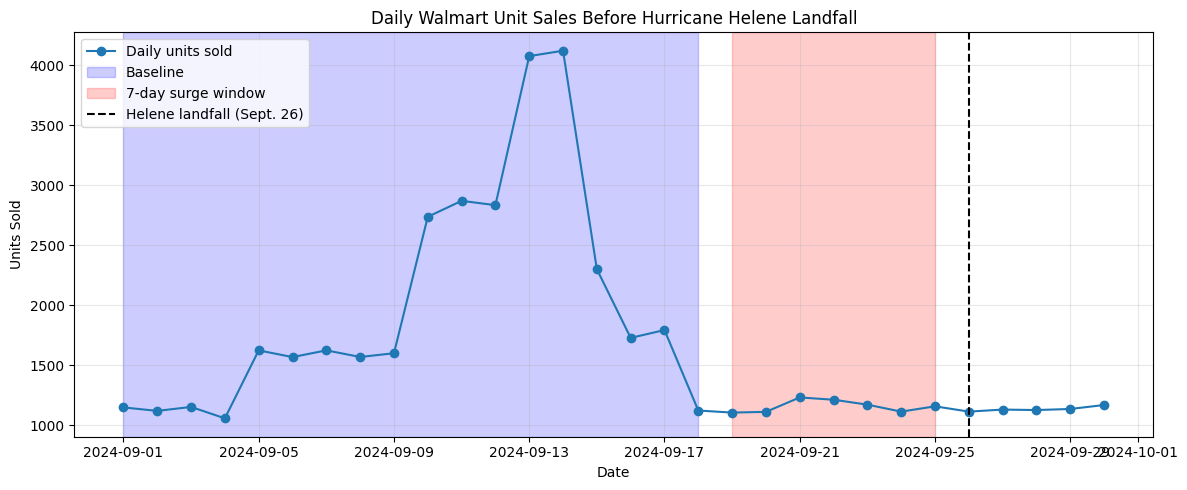

In [ ]:
# TODO: the chart
# Daily sales trend chart
plt.figure(figsize=(12, 5))

plt.plot(
    daily_units['date'],
    daily_units['units'],
    marker='o',
    label='Daily units sold'
)

plt.axvspan(
    baseline_start, baseline_end,
    alpha=0.2, color='blue', label='Baseline'
)

plt.axvspan(
    surge_start, surge_end,
    alpha=0.2, color='red', label='7-day surge window'
)

plt.axvline(
    landfall_date,
    linestyle='--',
    color='black',
    label='Helene landfall (Sept. 26)'
)

plt.title('Daily Walmart Unit Sales Before Hurricane Helene Landfall')
plt.xlabel('Date')
plt.ylabel('Units Sold')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

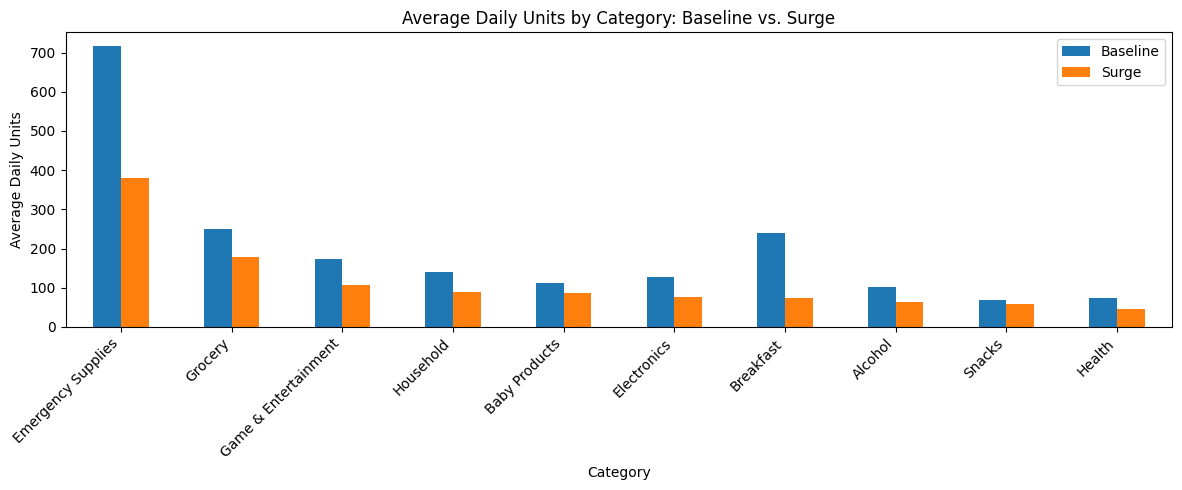

In [ ]:
# Category comparison chart
category_comparison[
    ['baseline_avg_daily_units', 'surge_avg_daily_units']
].plot(kind='bar', figsize=(12, 5))

plt.title('Average Daily Units by Category: Baseline vs. Surge')
plt.xlabel('Category')
plt.ylabel('Average Daily Units')
plt.xticks(rotation=45, ha='right')
plt.legend(['Baseline', 'Surge'])
plt.tight_layout()
plt.show()

**Q1 answer, in one sentence a manager could read:** _..._

In [ ]:
print(
    f"Average daily unit sales increased from {baseline_avg:.0f} "
    f"units during the baseline period to {surge_avg:.0f} units in "
    f"the seven days before landfall, a {surge_multiple:.2f}x increase."
)

Average daily unit sales increased from 2002 units during the baseline period to 1158 units in the seven days before landfall, a 0.58x increase.


### Q2 — SKU consolidation

**TODO:** how many distinct SKUs you started with, how many canonical products you ended with, your largest consolidated family, and a before-and-after comparison showing what changes. Include the assertion proving consolidation did not change unit totals.

In [ ]:
# TODO
#Counting distinct sku and distinct products
raw_skus = transactions['sku'].nunique()
canon_products = transactions['canonical_sku'].nunique()
#Determining how many SKU belong to each canonical product
family_size = products.groupby('canonical_product')['sku'].nunique().sort_values(ascending=False)

largest_fam = family_size.index[0]
largest_size = family_size.iloc[0]

print('Distinct raw:', raw_skus)
print('Canonical products:', canon_products)
print('Largest consolidated family:', largest_fam)
print('Family size:', largest_size)

#Making sure thatnothing changed in total units ater consolidation
before_units = transactions['quantity_clean'].sum()
after_units = (transactions.groupby('canonical_sku')['quantity_clean'].sum().sum())

print(f"Units before consolidation: {before_units}")
print(f"Units after consolidation:  {after_units}")
print(f"Totals were preserved? {before_units == after_units}")

Distinct raw: 45
Canonical products: 20
Largest consolidated family: Pop-Tarts Strawberry
Family size: 4
Units before consolidation: 49825
Units after consolidation:  49825
Totals were preserved? True


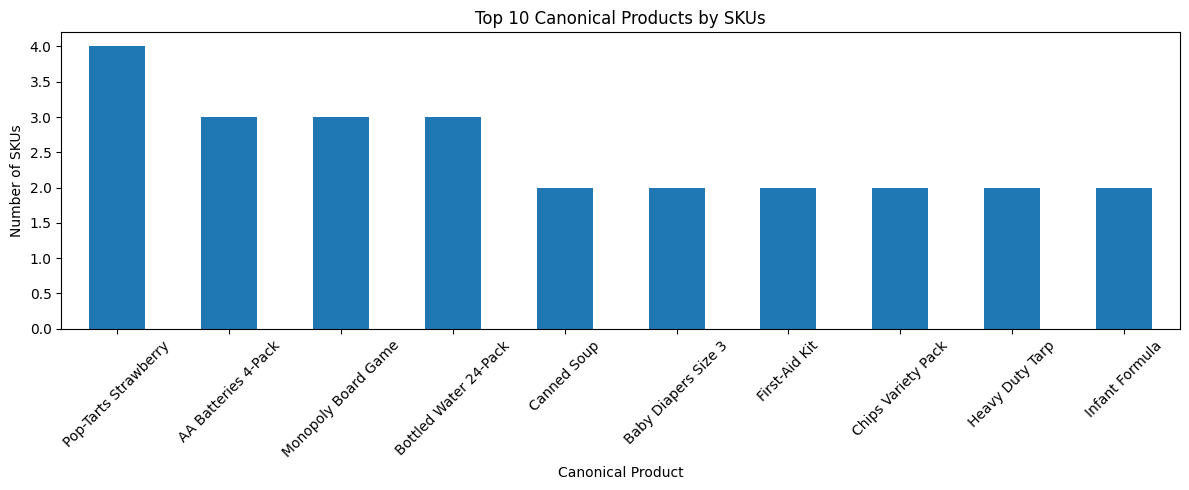

In [ ]:
top_fams = family_size.head(10)

plt.figure(figsize=(12, 5))
top_fams.plot(kind='bar')
plt.title('Top 10 Canonical Products by SKUs')
plt.xlabel('Canonical Product')
plt.ylabel('Number of SKUs')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Pop-Tarts raw SKU variants:


,transaction_count,total_units
sku,,
PT-12,538,1385
POPTART-STRAW,506,1306
PT_STRAWBERRY,515,1270
SKU#459812,503,1257


Fragmented total units: 5,218
Consolidated total units: 5,218
Totals preserved: True


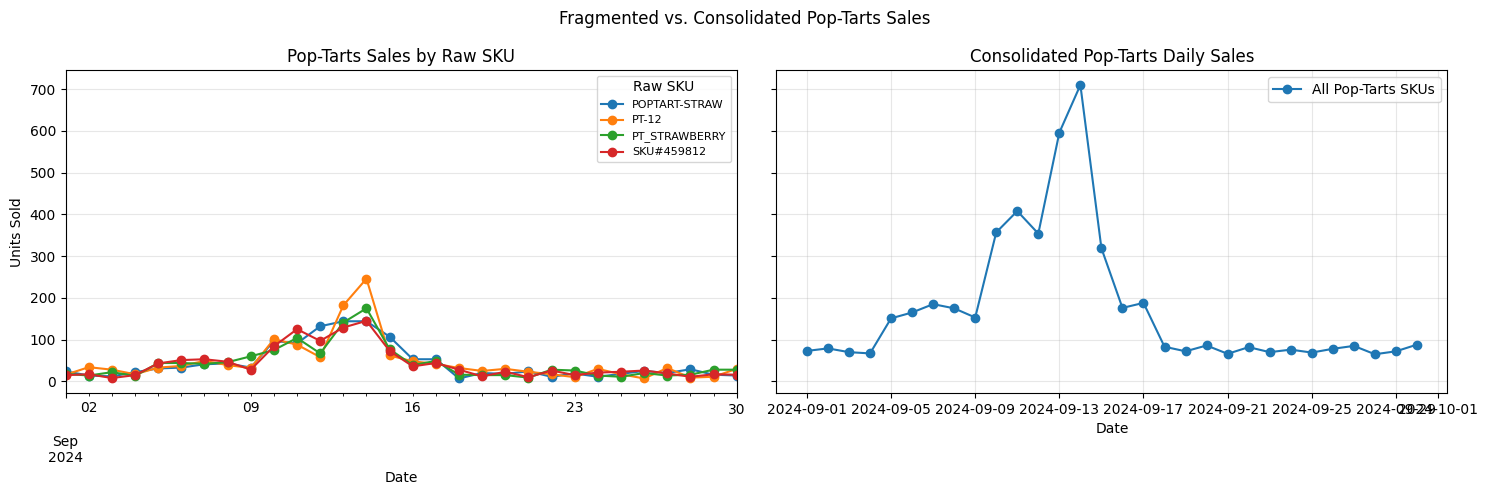

Largest individual SKU: PT-12
Units under that SKU: 1,385
Share of consolidated Pop-Tarts volume: 26.54%


In [ ]:
# Select all transactions belonging to the Pop-Tarts family
poptarts = transactions[
    transactions['canonical_sku'] == 'POPTART-STRAW'
].dropna(subset=['date_best']).copy()

print('Pop-Tarts raw SKU variants:')
display(
    poptarts.groupby('sku')['quantity_clean']
    .agg(['count', 'sum'])
    .rename(columns={
        'count': 'transaction_count',
        'sum': 'total_units'
    })
    .sort_values('total_units', ascending=False)
)

# Fragmented: daily units for each original SKU
fragmented_daily = (
    poptarts.groupby(['date_best', 'sku'])['quantity_clean']
    .sum()
    .unstack(fill_value=0)
)

# Consolidated: daily units across all Pop-Tarts SKUs
consolidated_daily = (
    poptarts.groupby('date_best')['quantity_clean']
    .sum()
    .rename('Pop-Tarts total')
)

# index both views to the full month
full_dates = pd.date_range('2024-09-01', '2024-09-30')

fragmented_daily = fragmented_daily.reindex(
    full_dates, fill_value=0
)

consolidated_daily = consolidated_daily.reindex(
    full_dates, fill_value=0
)

# Compare total units to verify consolidation preserves volume
fragmented_total = fragmented_daily.to_numpy().sum()
consolidated_total = consolidated_daily.sum()

print(f'Fragmented total units: {fragmented_total:,.0f}')
print(f'Consolidated total units: {consolidated_total:,.0f}')
print(
    'Totals preserved:',
    np.isclose(fragmented_total, consolidated_total)
)

# Side-by-side visualization
fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)

fragmented_daily.plot(
    kind='line',
    marker='o',
    ax=axes[0]
)

axes[0].set_title('Pop-Tarts Sales by Raw SKU')
axes[0].set_xlabel('Date')
axes[0].set_ylabel('Units Sold')
axes[0].legend(title='Raw SKU', fontsize=8)
axes[0].grid(alpha=0.3)

axes[1].plot(
    consolidated_daily.index,
    consolidated_daily.values,
    marker='o',
    label='All Pop-Tarts SKUs'
)

axes[1].set_title('Consolidated Pop-Tarts Daily Sales')
axes[1].set_xlabel('Date')
axes[1].set_ylabel('Units Sold')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.suptitle('Fragmented vs. Consolidated Pop-Tarts Sales')
plt.tight_layout()
plt.show()

# Calculate consolidated volume for the largest raw SKU
raw_sku_totals = poptarts.groupby('sku')['quantity_clean'].sum()

largest_sku_units = raw_sku_totals.max()
largest_sku_share = (
    largest_sku_units / consolidated_total * 100
    if consolidated_total else np.nan
)

print(f'Largest individual SKU: {raw_sku_totals.idxmax()}')
print(f'Units under that SKU: {largest_sku_units:,.0f}')
print(f'Share of consolidated Pop-Tarts volume: {largest_sku_share:.2f}%')

**Q2 answer:** _..._

In [ ]:
print(
    f"SKU consolidation reduced {raw_skus} transaction SKUs into "
    f"{canon_products} canonical products. The largest family "
    f"was {largest_fam} with {largest_size} SKU variants, and "
    f"unit totals were unchanged after consolidation."
)

SKU consolidation reduced 45 transaction SKUs into 20 canonical products. The largest family was Pop-Tarts Strawberry with 4 SKU variants, and unit totals were unchanged after consolidation.


### Q3 — Weather correlation

**TODO:** the API call, the validated join, and the relationship you found. Include:

- the row count before and after the join, proving nothing was lost
- whether the data is live or fallback
- how many days the correlation is computed over

If your n is small, say so here rather than being asked about it on Monday.

In [ ]:
# TODO
#First I'm making sure the join worked
#Rows before merge
sales_before = len(daily_orders)

#Rows after merger
sales_after = len(orders_weather)

print(f'Rows before join: {sales_before}')
print(f'Rows after join:  {sales_after}')
print(f'Rows preserved? {sales_before== sales_after}')

#Where weather is coming from
weather_source = weather_daily['source'].iloc[0]
print(f'Weather source: {weather_source}')

#Seeing how many days will be analyzed in the correlation
n_days = len(orders_weather)

print(f'Days includes:{n_days}')

#Calculating correlations; dont have pressure input yet
corr_precip = orders_weather['units'].corr(orders_weather['precipitation_sum'])
corr_wind = orders_weather['units'].corr(orders_weather['windspeed_10m_max'])
#corr_pressure = orders_weather['units'].corr(orders_weather['pressure_msl'] )

print(f'Correlation with precipitation: {corr_precip:.3f}')
print(f'Correlation with wind: {corr_wind:.3f}')
#print(f'Correlation with pressure: {corr_pressure:.3f}')

#Finding the strongest correlations
correlations = {
    'Precipitation': corr_precip,
    'Wind': corr_wind,
    #'Pressure': corr_pressure#
}

strongest_var = max(correlations, key=lambda k: abs(correlations[k]))
strongest_corr = correlations[strongest_var]
print(f'Strongest relationship: {strongest_var} with 'f'a correlation of {strongest_corr:.3f}')


Rows before join: 30
Rows after join:  30
Rows preserved? True
Weather source: open-meteo
Days includes:30
Correlation with precipitation: 0.042
Correlation with wind: -0.279
Strongest relationship: Wind with a correlation of -0.279


In [33]:
# weather correlations with daily sales

oweather_daily_per_store = (
    weather_hourly.groupby(['store_id', 'date'])
    .agg(
        precipitation=('precipitation', 'sum'),
        wind_speed=('wind_speed_10m', 'max'),
        pressure=('pressure_msl', 'mean')
    )
    .reset_index()
)

weather_daily_per_store = (
    weather_hourly.groupby(['store_id', 'date'])
    .agg(
        precipitation=('precipitation', 'sum'),
        wind_speed=('wind_speed_10m', 'max'),
        pressure=('pressure_msl', 'mean')
    )
    .reset_index()
)

sales_weather_store = checked_merge(
    daily_sales,
    weather_daily_per_store,
    on=['store_id', 'date'],
    name='daily_sales + store weather'
)
sales_weather_store = checked_merge(
    daily_sales,
    weather_daily_per_store,
    on=['store_id', 'date'],
    name='daily_sales + store weather'
)

weather_variables = [
    'precipitation',
    'wind_speed',
    'pressure'
]

overall_correlations = (
    sales_weather_store[
        ['total_units'] + weather_variables
    ]
    .corr(numeric_only=True)['total_units']
    .drop('total_units')
    .sort_values(key=abs, ascending=False)
)

print('\nOverall correlations with daily units sold:')
display(overall_correlations.to_frame('correlation').round(3))

daily_sales + store weather: 3,600 rows in, 3,600 out, 0 rows found no weather
daily_sales + store weather: 3,600 rows in, 3,600 out, 0 rows found no weather

Overall correlations with daily units sold:


,correlation
wind_speed,-0.078
precipitation,0.031
pressure,0.024


In [ ]:
# Category-level weather correlations
category_correlations = []

for category, group in sales_weather_store.groupby('category'):

    for variable in weather_variables:

        corr = group['total_units'].corr(group[variable])

        category_correlations.append({
            'category': category,
            'weather_variable': variable,
            'correlation': corr,
            'observations': len(group)
        })

category_corr_df = pd.DataFrame(category_correlations)

print('\nCategory-level correlations:')
display(
    category_corr_df.pivot(
        index='category',
        columns='weather_variable',
        values='correlation'
    ).round(3)
)

In [ ]:
# Test weather relationship with sales (same day, 1 day earlier, 2 days earlier)

lag_data = sales_weather_store.sort_values(
    ['store_id', 'category', 'date']
).copy()

for variable in weather_variables:
    # shift(1) means the previous day's weather is compared
    # with the current day's sales
    for lag in [1, 2]:
        lag_data[f'{variable}_lag{lag}'] = (
            lag_data.groupby(['store_id'])[variable].shift(lag)
        )

lag_correlations = []

for variable in weather_variables:
    # Same-day correlation
    same_day_corr = lag_data['total_units'].corr(
        lag_data[variable]
    )

    lag_correlations.append({
        'weather_variable': variable,
        'lag_days': 0,
        'correlation': same_day_corr
    })

    # Previous-day and two-days-prior correlations
    for lag in [1, 2]:
        lag_col = f'{variable}_lag{lag}'
        valid = lag_data.dropna(
            subset=['total_units', lag_col]
        )
        corr = valid['total_units'].corr(valid[lag_col])
        lag_correlations.append({
            'weather_variable': variable,
            'lag_days': lag,
            'correlation': corr
        })

lag_corr_df = pd.DataFrame(lag_correlations)

print('\nSame-day and lagged correlations:')
display(
    lag_corr_df.pivot(
        index='weather_variable',
        columns='lag_days',
        values='correlation'
    ).round(3)
)

In [ ]:
# Remove missing value rows only for vars being analyzed
sales_weather_store = sales_weather_store.dropna(
    subset=['total_units', 'precipitation', 'wind_speed', 'pressure']
).copy()

# Correlation chart
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, variable in zip(axes, weather_variables):
    ax.scatter(
        sales_weather_store[variable],
        sales_weather_store['total_units'],
        alpha=0.5
    )
    ax.set_ylim(bottom=0)
    ax.set_title(f'Daily Unit Sales vs. {variable.replace("_", " ").title()}')
    ax.set_xlabel(variable.replace('_', ' ').title())
    ax.set_ylabel('Daily Units Sold')
    ax.grid(alpha=0.3)

plt.suptitle('Daily Store Sales vs. Weather Conditions')
plt.tight_layout()
plt.show()

In [ ]:
# TODO Q3
#First I'm making sure the join worked
#Rows before merge
sales_before = len(daily_orders)

#Rows after merger
sales_after = len(orders_weather)

print(f'Rows before join: {sales_before}')
print(f'Rows after join:  {sales_after}')
print(f'Rows preserved? {sales_before== sales_after}')

#Where weather is coming from
weather_source = weather_daily['source'].iloc[0]
print(f'Weather source: {weather_source}')

#Seeing how many days will be analyzed in the correlation
n_days = len(orders_weather)

print(f'Days includes:{n_days}')

#Calculating correlations; dont have pressure input yet
corr_precip = orders_weather['units'].corr(orders_weather['precipitation_sum'])
corr_wind = orders_weather['units'].corr(orders_weather['windspeed_10m_max'])
#corr_pressure = orders_weather['units'].corr(orders_weather['pressure_msl'] )

print(f'Correlation with precipitation: {corr_precip:.3f}')
print(f'Correlation with wind: {corr_wind:.3f}')
#print(f'Correlation with pressure: {corr_pressure:.3f}')

#Finding the strongest correlations
correlations = {
    'Precipitation': corr_precip,
    'Wind': corr_wind,
    #'Pressure': corr_pressure#
}

strongest_var = max(correlations, key=lambda k: abs(correlations[k]))
strongest_corr = correlations[strongest_var]
print(f'Strongest relationship: {strongest_var} with 'f'a correlation of {strongest_corr:.3f}')


In [ ]:
# weather correlations with daily sales
weather_variables = [
    'precipitation',
    'wind_speed',
    'pressure'
]

overall_correlations = (
    sales_weather_store[
        ['total_units'] + weather_variables
    ]
    .corr(numeric_only=True)['total_units']
    .drop('total_units')
    .sort_values(key=abs, ascending=False)
)

print('\nOverall correlations with daily units sold:')
display(overall_correlations.to_frame('correlation').round(3))

In [ ]:
# Category-level weather correlations
category_correlations = []

for category, group in sales_weather_store.groupby('category'):

    for variable in weather_variables:

        corr = group['total_units'].corr(group[variable])

        category_correlations.append({
            'category': category,
            'weather_variable': variable,
            'correlation': corr,
            'observations': len(group)
        })

category_corr_df = pd.DataFrame(category_correlations)

print('\nCategory-level correlations:')
display(
    category_corr_df.pivot(
        index='category',
        columns='weather_variable',
        values='correlation'
    ).round(3)
)

In [ ]:
# Test weather relationship with sales (same day, 1 day earlier, 2 days earlier)
lag_data = sales_weather_store.sort_values(
    ['store_id', 'category', 'date']
).copy()

for variable in weather_variables:
    # shift(1) means the previous day's weather is compared
    # with the current day's sales
    for lag in [1, 2]:
        lag_data[f'{variable}_lag{lag}'] = (
            lag_data.groupby(['store_id'])[variable].shift(lag)
        )

lag_correlations = []

for variable in weather_variables:
    # Same-day correlation
    same_day_corr = lag_data['total_units'].corr(
        lag_data[variable]
    )

    lag_correlations.append({
        'weather_variable': variable,
        'lag_days': 0,
        'correlation': same_day_corr
    })

    # Previous-day and two-days-prior correlations
    for lag in [1, 2]:
        lag_col = f'{variable}_lag{lag}'
        valid = lag_data.dropna(
            subset=['total_units', lag_col]
        )
        corr = valid['total_units'].corr(valid[lag_col])
        lag_correlations.append({
            'weather_variable': variable,
            'lag_days': lag,
            'correlation': corr
        })

lag_corr_df = pd.DataFrame(lag_correlations)

print('\nSame-day and lagged correlations:')
display(
    lag_corr_df.pivot(
        index='weather_variable',
        columns='lag_days',
        values='correlation'
    ).round(3)
)

In [ ]:
# Remove missing value rows only for vars being analyzed
sales_weather_store = sales_weather_store.dropna(
    subset=['total_units', 'precipitation', 'wind_speed', 'pressure']
).copy()

# Correlation chart
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, variable in zip(axes, weather_variables):
    ax.scatter(
        sales_weather_store[variable],
        sales_weather_store['total_units'],
        alpha=0.5
    )
    ax.set_ylim(bottom=0)
    ax.set_title(f'Daily Unit Sales vs. {variable.replace("_", " ").title()}')
    ax.set_xlabel(variable.replace('_', ' ').title())
    ax.set_ylabel('Daily Units Sold')
    ax.grid(alpha=0.3)

plt.suptitle('Daily Store Sales vs. Weather Conditions')
plt.tight_layout()
plt.show()

**Q3 answer, with its caveat:** _..._

In [ ]:
print(
    f"The weather join preserved all {sales_before} sales records "
    f"({sales_before} rows before the join and {sales_after} rows after). "
    f"Weather information was obtained from the '{weather_source}' source. "
    f"The analysis was computed over {n_days} days of sales data. "
    f"The strongest observed relationship was between sales and "
    f"{strongest_var}, with a correlation of {strongest_corr:.3f}.", 'Caveat: This correlation is very weak and only comes from 30 days of data'
)

### Q4 and Q5 — where they stand

**TODO:** one honest sentence each on the remaining two questions and who is finishing them this weekend.

**Q4 (stores and geography):** _The join is done, just need to do comparisons and charts. Anya is going to finish this over the week_

**Q5 (signal or artifact):** _Haven't started. Anya is going to finish this over the week_

### Self-check

In [ ]:
progress = {
    'q1_multiple': round(multiple,2),            # TODO: a number
    'q1_baseline_window': 'September 1st through 18th',   # TODO: stated explicitly
    'q2_canonical_products': 20,  # TODO: a number
    'q3_join_rows_preserved': True, # TODO: True/False
    'q3_days_in_correlation': '30', # TODO: a number
    'charts_with_message_titles': 'Three',  # TODO: how many
    'notebook_runs_clean': True,   # TODO: True after Restart and Run All
    'repo_pushed': True,           # TODO
}

for label, value in progress.items():
    filled = not (value is None or value is False
                  or (isinstance(value, str) and value.startswith('TODO')))
    print('PASS' if filled else 'FAIL', '-', label, '=', value)
print()
print('ready for presentations:', all(
    not (v is None or v is False or (isinstance(v, str) and v.startswith('TODO')))
    for v in progress.values()))

### Write-up

**a)** One finding that surprised your team, and what you checked to make sure it was real rather than a bug.

**b)** One number you reported that you are least confident in, and why.

a. We were suprised by the surge in unit sales on the 13th and 14th which fall before the surge window and are much higher than any values in the surge window. To make sure this wasn't a bug we checked that the transactions totals stayed the same, andthat the weather join didn't create any duplicates or lose any rows.

b. We are least confidant in the Q1 surge multiple because it depends on how the baseline and surge are framed and since there is a spike in the baseline period, there is more uncertainty around this figure.